# K562 + TNF-alpha: figures

Manuscript figures from the cell-state trajectories of `02_GetTrajectories.ipynb` (time, trajectory clusters, terminal fate probabilities on the OT-UMAP) and the single-lineage tradeSeq fit of `04_TradeSeqFits.ipynb` (association volcano). Figures are saved to `EXP_DIR/figures/`.

Fate `0` (`Inflammatory-hi`) is the strong NF-kB fate and fate `1` (`Erythroid-like`) the weak NF-kB fate. Time tags are 10 minutes apart (0-110 min).

In [1]:
import os
from pathlib import Path

import pandas as pd
import scanpy as sc

import chronopack as cp

# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
EXP_DIR = DATA_DIR / "k562-tnfa.hg38.rep"
TRADESEQ_DIR = EXP_DIR / "intmd/sc-K562-1e4_to_tradeSeq.fixed"
FIG_DIR = EXP_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MINUTES_PER_TAG = 10
FATE_NAMES = {"0": "Inflammatory-hi", "1": "Erythroid-like"}


## Data

The full-gene object (the gene panels and correlations use genes outside the HVGs). The OT-UMAP is rotated so that time runs upward; `flip_x=True` mirrors it to the orientation of the manuscript figures.

In [2]:
adata = sc.read_h5ad(EXP_DIR / "output/adata_full.1e4-variant.chk1.h5ad")
BASIS = cp.tl.rotate_embedding_to_time(adata, basis="ot_umap", key_added="ot_umap_rot", flip_x=True)
adata


AnnData object with n_obs × n_vars = 6857 × 20036
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden', 'traj_clusters', 'terminal_fate_probs_traj_0', 'terminal_fate_probs_traj_1', 'fate_0', 'fate_1', 'fate_entropy', 'fate_maxprob', 'traj_clusters_mass_ret_cell'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'chronopack', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'ot_graph', 'pca', 'phase_colors', 'sample_colors', 'scrublet', 'terminal_cell_dist_idx_last', 'terminal_fate_probs_traj_fates', 'terminal_fate_probs_traj_names', 'time_group_colors', 'traj_clusters', 'traj_clusters_colors', 'tra

## Time

OT-UMAP coloured by sampling time in minutes.

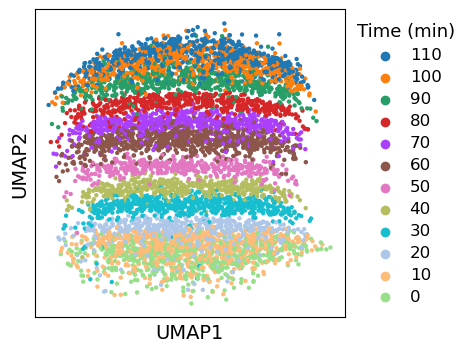

In [3]:
fig = cp.pl.cell_trajectories.time_minutes(
    adata,
    embedding_basis=BASIS,
    minutes_per_tag=MINUTES_PER_TAG,
    size=40,
    output=FIG_DIR / "umap_time_minutes.pdf",
)


## Trajectory clusters

Cells coloured by their trajectory cluster (`traj_clusters`).

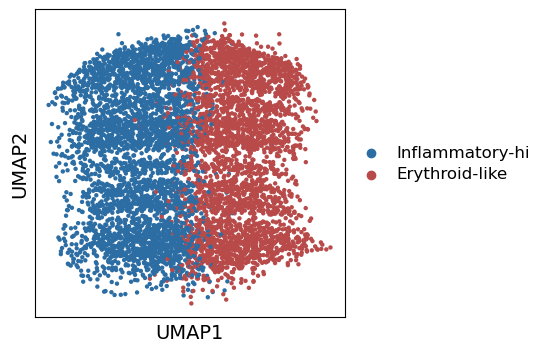

In [4]:
fig = cp.pl.cell_trajectories.trajectory_cell_types(
    adata,
    labels=FATE_NAMES,
    palette=["#2C6DA4", "#B84A4A"],
    embedding_basis=BASIS,
    size=40,
    output=FIG_DIR / "umap_cell_type_custom.pdf",
)


## Terminal fate probabilities

Top: probability of the weak NF-kB fate (`1`, red) and of the strong NF-kB fate (`0`, blue). Bottom: normalized fate entropy and maximum fate probability.

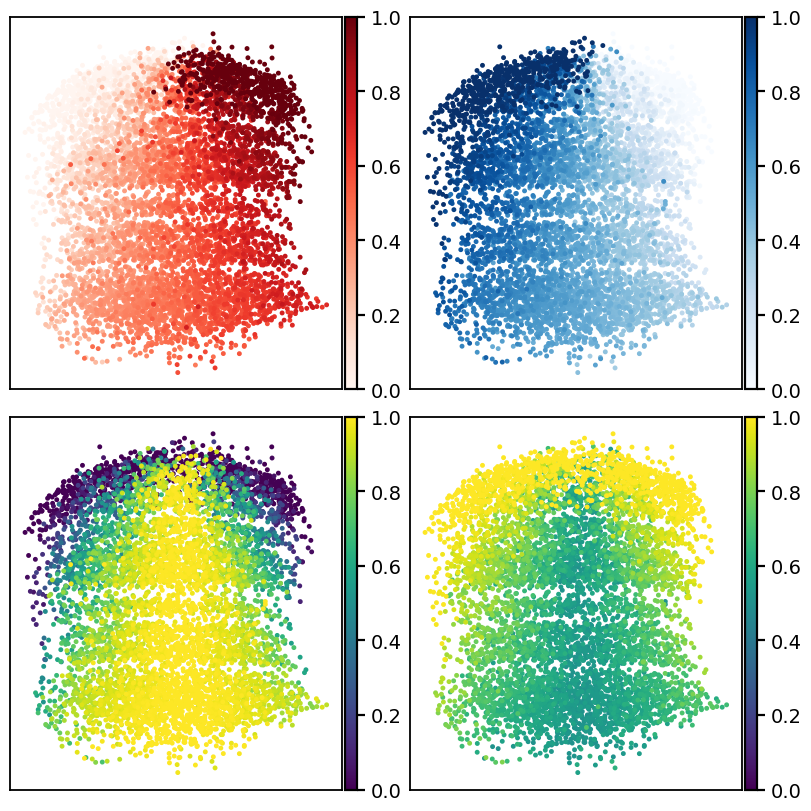

In [5]:
fig = cp.pl.cell_trajectories.fate_probability_panels(
    adata,
    embedding_basis=BASIS,
    which_two=(1, 0),
    size=50,
    figsize=(8, 8),
    cbar_ticklabel_size=14,
    cbar_tick_width=1.6,
    cbar_tick_length=6,
    umap_border_width=1.3,
    output=FIG_DIR / "fate_umap_2x2.pdf",
)


## Genes correlated with fate in the first time bin

Spearman correlation, in the first time bin, between each gene's expression (log1p) and the fate-probability difference `fate_1 - fate_0` (positive: weak NF-kB fate). Genes above their bin mean in fewer than 10% of the cells are skipped. The plot shows the top 20 genes in each direction with q < 0.05.

In [6]:
res = cp.tl.early_fate_correlations(
    adata,
    fate0_key="fate_0",
    fate1_key="fate_1",
    time_key="time",
    early_bins=(1,),
    layer="log1p",
    method="spearman",
)
sig = res.query("qval < 0.05")
display(sig.head(10), sig.tail(10))


,gene,r,pval,qval,detect_rate_early
0,HBZ,0.706048,7.670907e-98,3.242492e-94,0.488300
1,HBG2,0.704004,4.802822e-97,1.015076e-93,0.581903
2,HBG1,0.690098,8.386498e-92,1.181658e-88,0.558502
3,HBA1,0.544699,8.381407e-51,8.857051e-48,0.500780
4,HEMGN,0.518312,2.349886e-45,1.986593e-42,0.546022
5,HBA2,0.416133,3.102212e-28,1.639131e-25,0.262090
6,BLVRB,0.377558,3.786966e-23,1.600751e-20,0.569423
7,GSTP1,0.319104,1.224064e-16,3.449413e-14,0.602184
8,GYPB,0.302070,5.444439e-15,1.278536e-12,0.263651
9,GYPA,0.297291,1.511185e-14,3.193889e-12,0.255850


,gene,r,pval,qval,detect_rate_early
4217,SLC2A3,-0.298732,1.113036e-14,2.476212e-12,0.218409
4218,SH3BGRL3,-0.302568,4.889906e-15,1.215861e-12,0.488300
4219,KRT18,-0.311821,6.391658e-16,1.688596e-13,0.572543
4220,LGALS1,-0.336002,2.214157e-18,6.685173e-16,0.541342
4221,CLIC1,-0.344726,2.525348e-19,8.211265e-17,0.611544
4222,CD3D,-0.346826,1.482084e-19,5.220642e-17,0.277691
4223,TMSB10,-0.347282,1.319435e-19,5.070229e-17,0.567863
4224,EPHB6,-0.392006,5.639082e-25,2.648489e-22,0.347894
4225,VIM,-0.459419,8.687350e-35,5.245918e-32,0.283931
4226,TMSB4X,-0.500176,7.038155e-42,4.958380e-39,0.594384


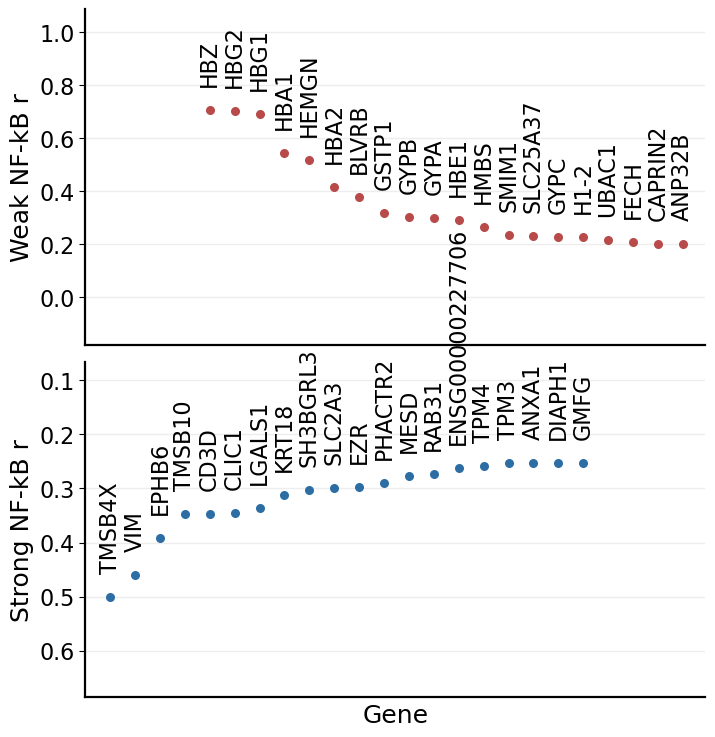

In [7]:
fig = cp.pl.cell_trajectories.top_fate_correlations(
    res,
    top_n=20,
    x_step=2.2,
    gap_steps=-15,
    point_size=30,
    left_pad_steps=1.0,
    right_pad_steps=0.9,
    tick_label_size=16,
    axis_label_size=18,
    abs_neg_ticks=True,
    label_offset_frac=0.07,
    y_pad_frac=0.75,
    label_fontsize=16,
    top_ylabel="Weak NF-kB r",
    bot_ylabel="Strong NF-kB r",
    output=FIG_DIR / "early_fate_corrs.pdf",
)


{'HBG2': np.float64(-0.7040038653471438), 'TMSB4X': np.float64(0.5001756394352911)}

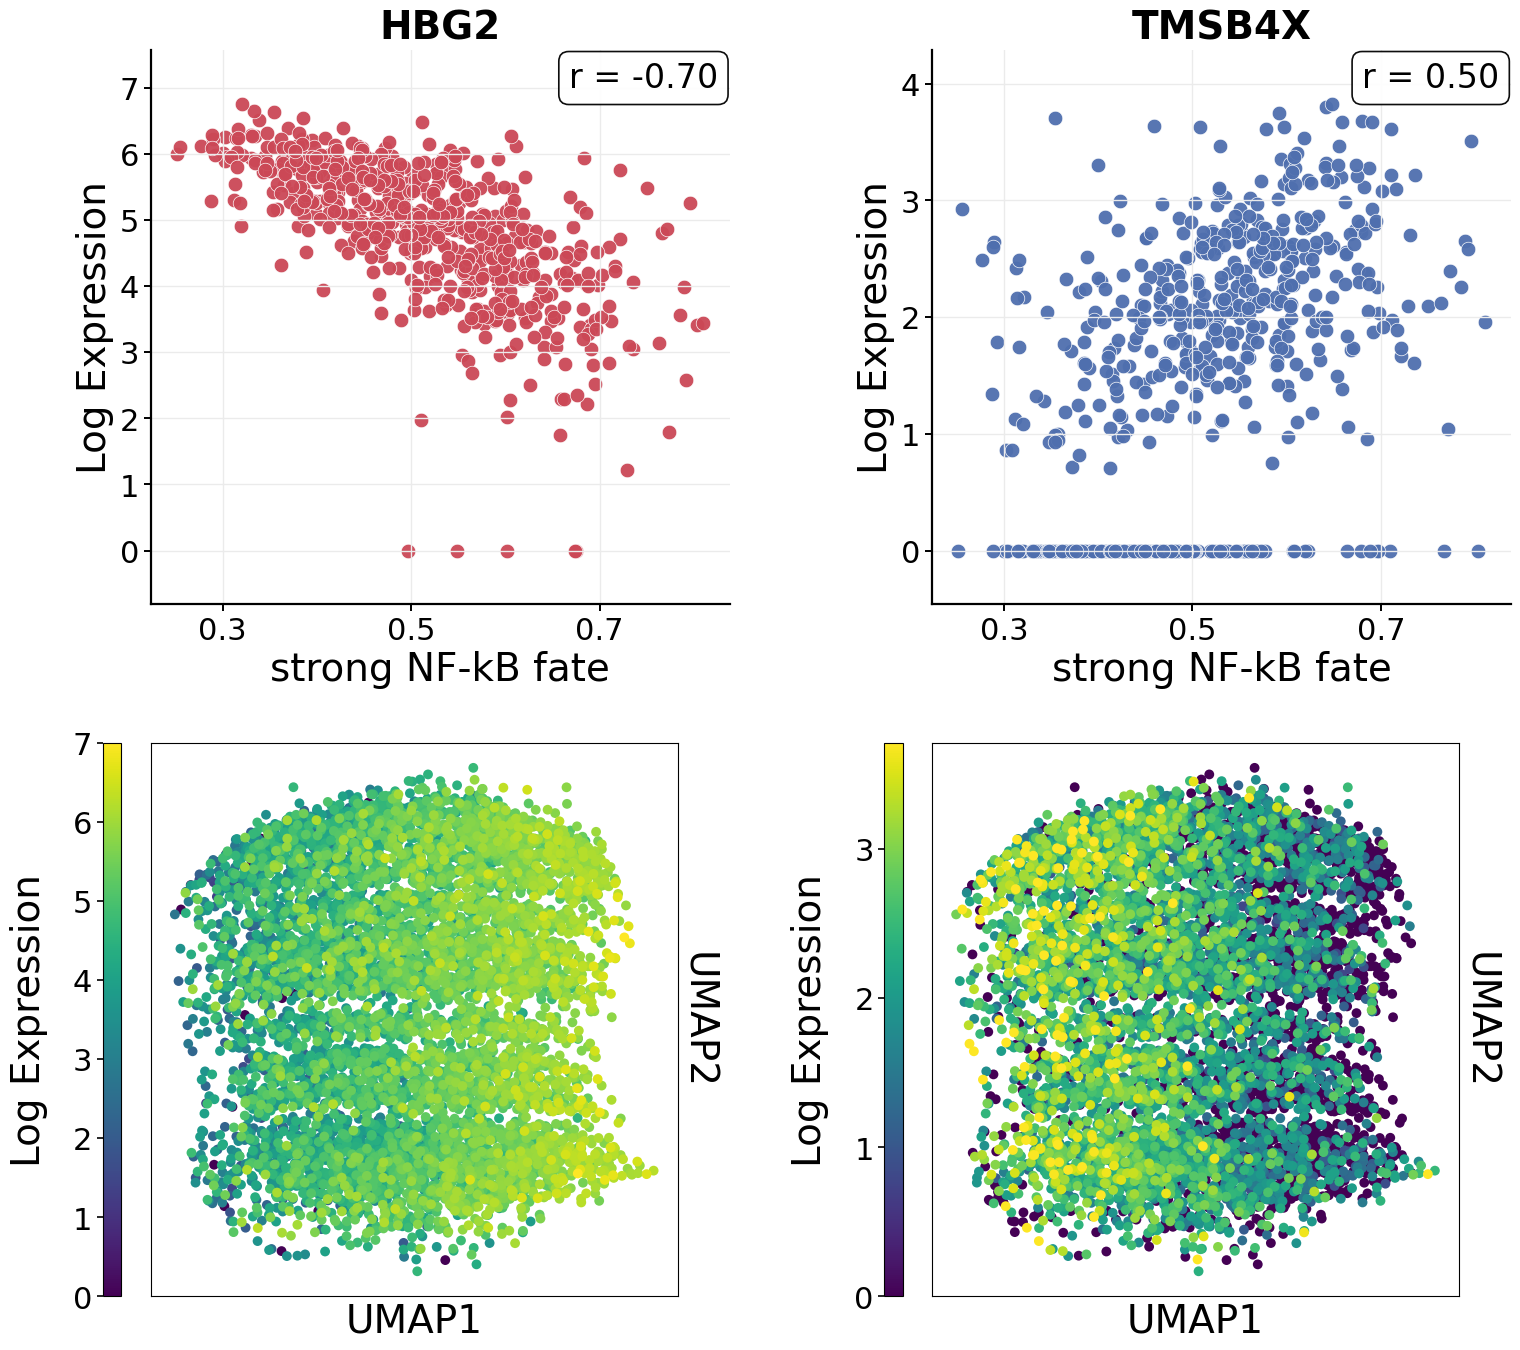

In [8]:
fig = cp.pl.cell_trajectories.two_gene_fate_scatter(
    adata,
    ("HBG2", "TMSB4X"),
    colors=("#CB4856", "#4F6FAE"),
    fate_key="fate_0",
    x_label="strong NF-kB fate",
    xlim="auto",  # fit to the earliest bin's fate values rather than 0-1
    xticks=(0.3, 0.5, 0.7),
    embedding_basis=BASIS,
    cmap="viridis",
    expression_vmax={"HBG2": 7},
    colorbar_tick_interval=1.0,
    figsize=(16, 14),
    dot_size=110,
    umap_dot_size=200,
    font_tick=22,
    row_hspace=0.25,
    col_wspace=0.35,
    output=FIG_DIR / "HBG2_TMSB4X_scatter_umap_earlybin.pdf",
)
fig.spearman_r


## Gene dynamics: association volcano

Single-lineage association test of the 4-knot tradeSeq screen (`asso_df.1trajectory.nknots4.csv`). The x-axis is each gene's signed maximum log2 fold change against the start of its fitted curve (`sce_screen.1trajectory.nknots4.rds`, 100 points, pseudocount 0.01).

In [9]:
asso_df = pd.read_csv(TRADESEQ_DIR / "asso_df.1trajectory.nknots4.csv", index_col=0)
asso_df["signedMaxLog2FC_start"] = cp.tl.signed_max_log2fc_from_start(
    TRADESEQ_DIR, asso_df.index, n_points=100, pseudocount=0.01
)
asso_df.head()


,waldStat_1,df_1,pvalue_1,meanLogFC,qval_1,signedMaxLog2FC_start
NFKBIA,1967.377557,3,0.0,2.806293,0.0,4.732194
CXCL3,742.323899,3,0.0,2.786376,0.0,4.440308
CD69,602.364734,3,0.0,3.454632,0.0,5.346873
CD83,566.998711,3,0.0,2.128998,0.0,4.029928
ARL4A,466.569370,3,0.0,0.365352,0.0,0.764911


Genes with q < 0.01 are coloured by direction when |log2FC| >= 0.5. The log10 Wald axis is compressed below the Wald statistic of the gene whose q-value is closest to 0.01 (`y_break="fdr"`, also the dashed line). The top 30 genes by Wald statistic are labelled.

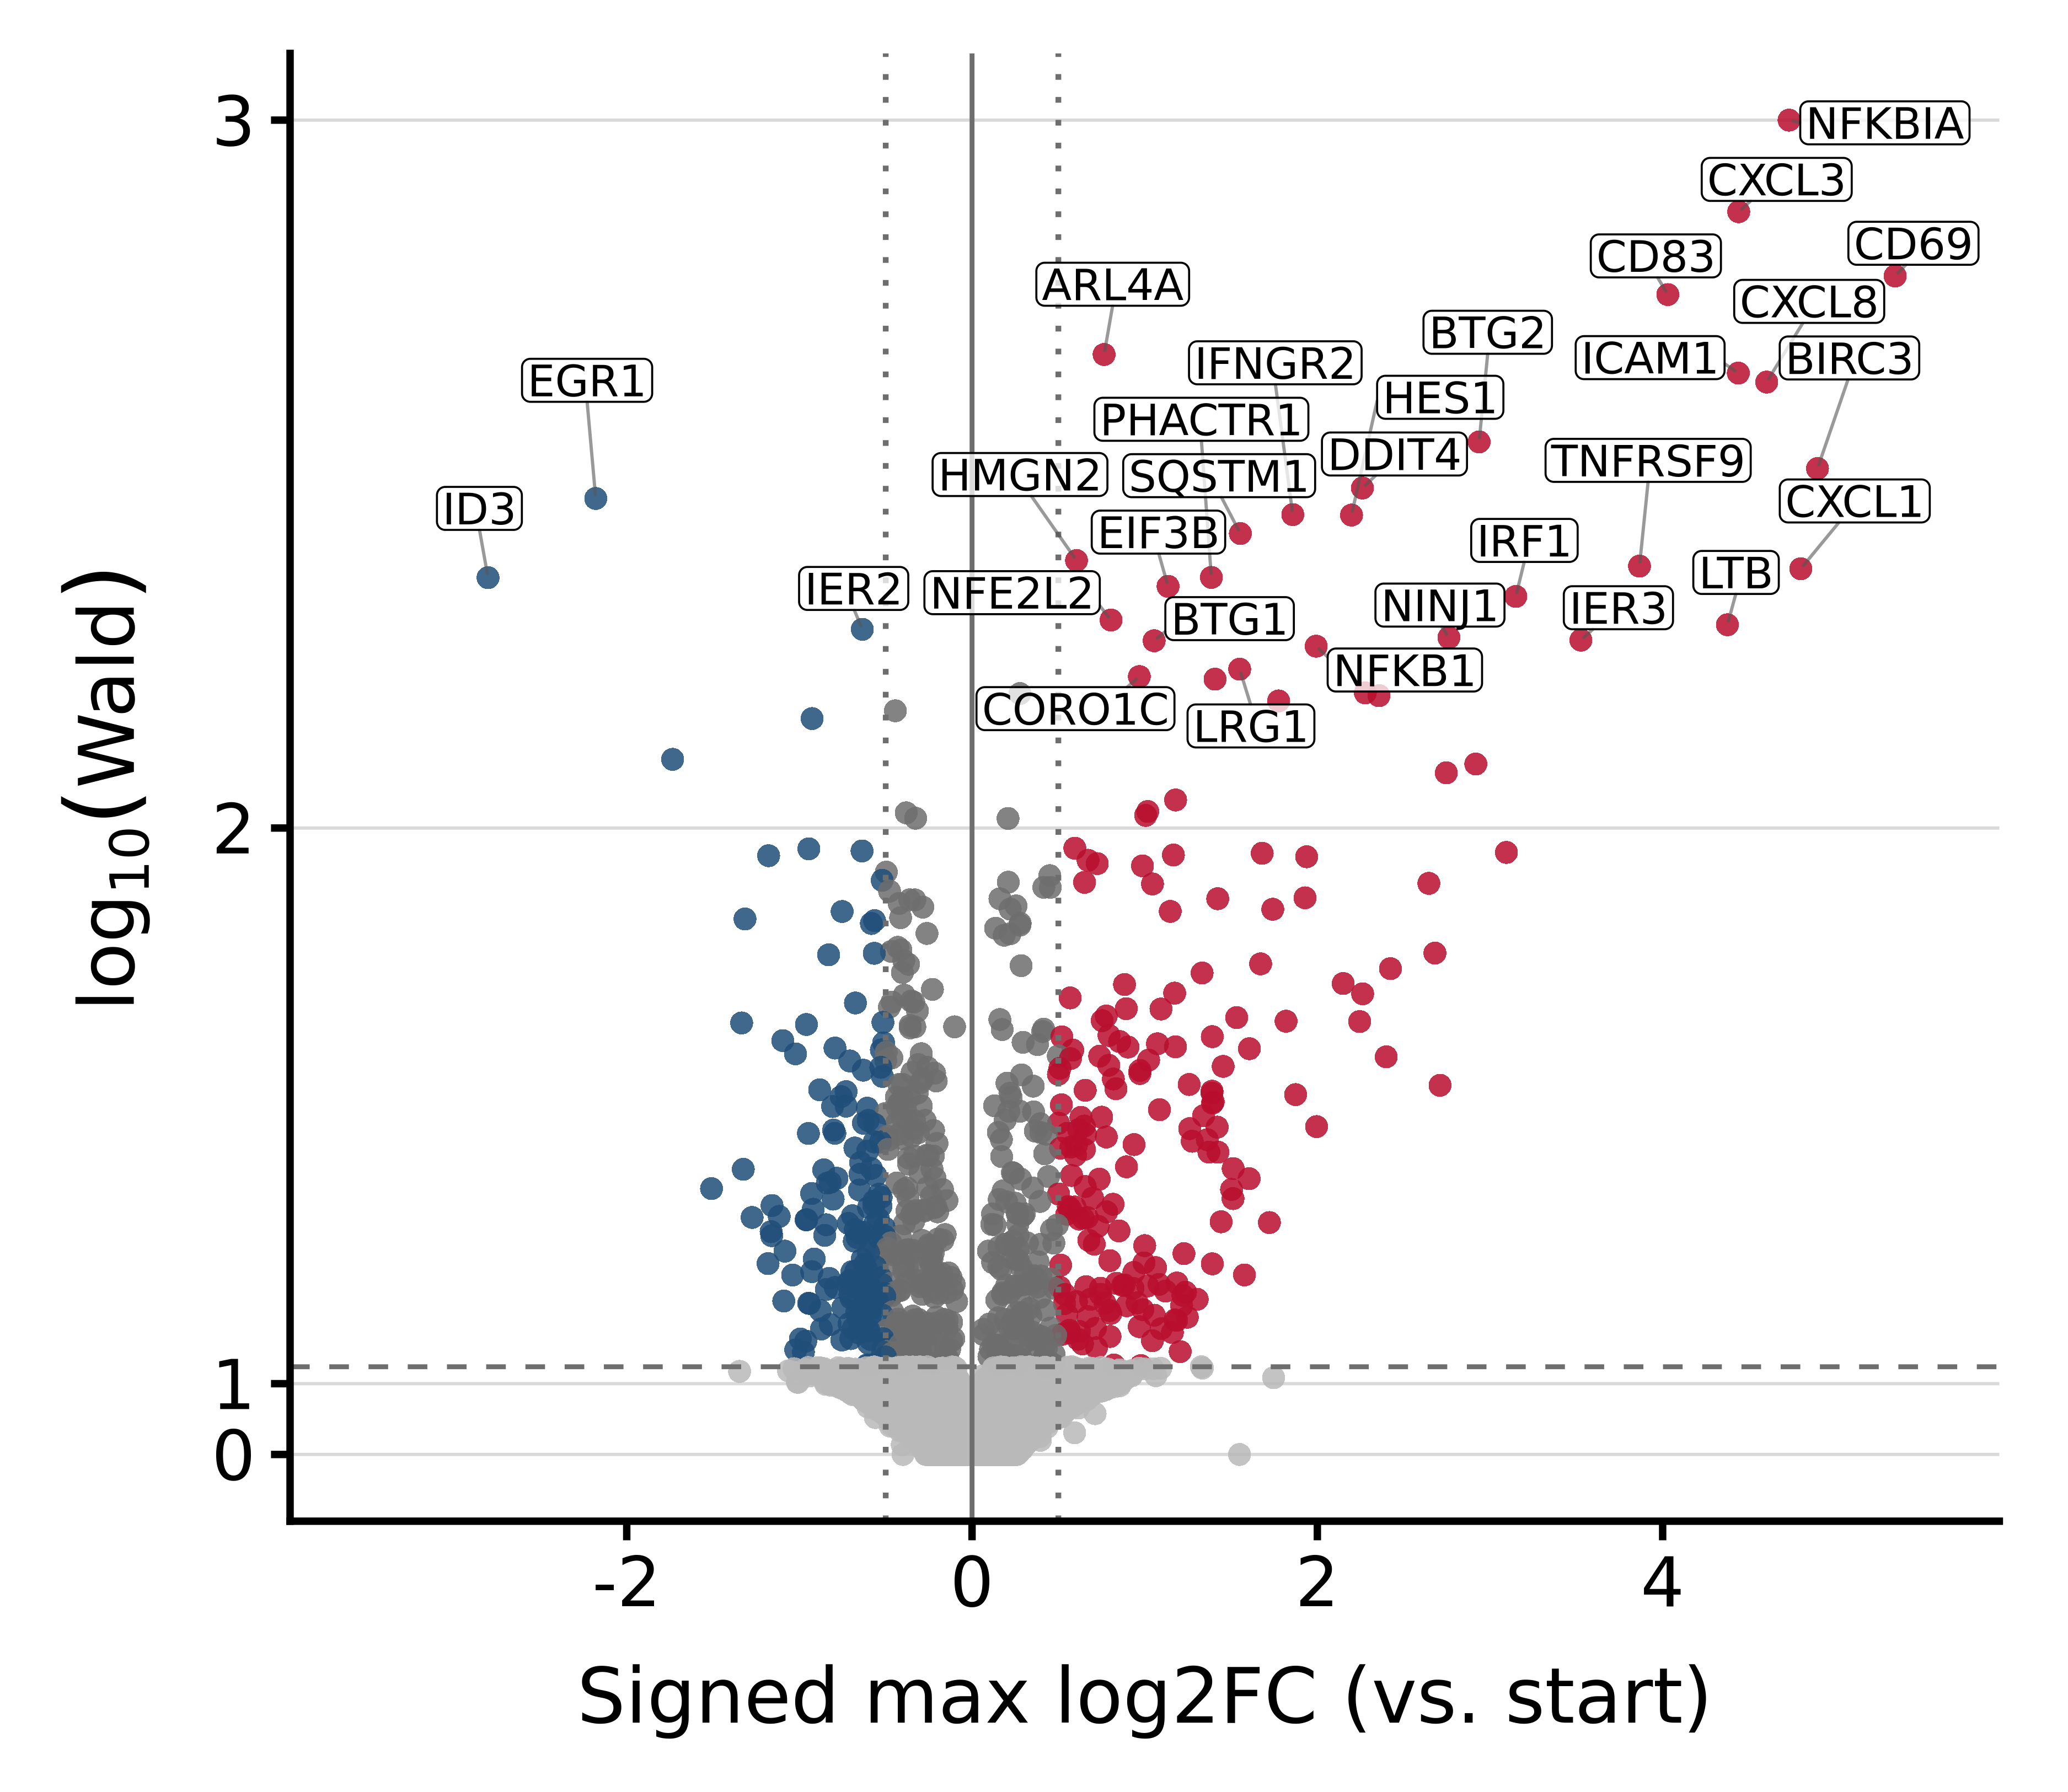

In [10]:
volcano = cp.pl.association_volcano(
    asso_df,
    fdr_thresh=0.01,
    l2fc_thresh=0.5,
    x_lim=(-3.5, 5.5),
    y_lim=(1, 1000),
    y_lower_scale=0.1,
    y_break="fdr",
    top_labels=30,
    label_rank_by="wald",
    label_logfc_abs=True,
    label_only_pass=False,
    label_x_nudge=0.05,
    label_y_offset_frac=0.05,
    label_min_vgap_frac=0.012,
    label_size=4,
    axis_text_size=18,
    axis_title_size=20,
    output=FIG_DIR / "volcano.l2fc05.q01.pdf",
)
volcano


## Gene dynamics: two-lineage NB-GAM curves

Fitted curves (95% bands) of the 8-knot two-lineage tradeSeq fit (`04_TradeSeqFits.TwoLineage.ipynb`; if its `sce.2trajectory.nknots8.rds` is not in the data folder, just the plotted genes are fitted here, which gives the same curves in a few minutes): lineage 1 is the inflammatory-high trajectory cluster, lineage 2 the erythroid-like one. Points are cells (counts scaled to the reference library size of the curves, log1p), colored by their highest-weight lineage in the soft memberships (`cell_weights.csv`); white circles are each lineage's weighted mean per time point.

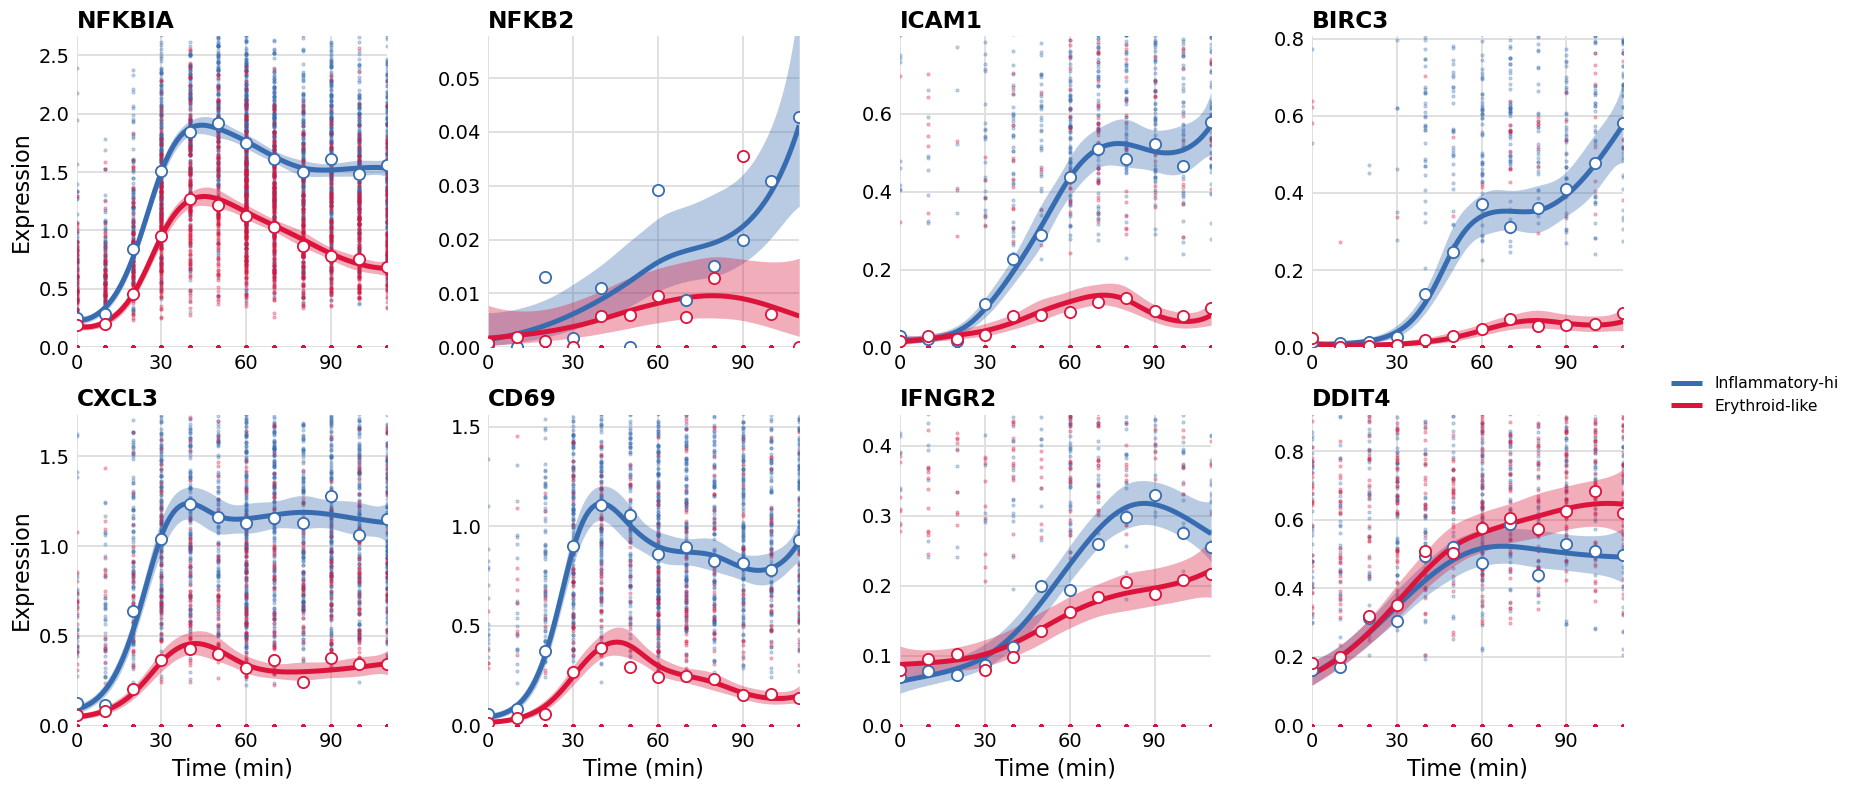

In [11]:
GENES = ["NFKBIA", "NFKB2", "ICAM1", "BIRC3", "CXCL3", "CD69", "IFNGR2", "DDIT4"]

# The stored two-lineage fit from 04_TradeSeqFits.TwoLineage.ipynb if present; otherwise fit only these genes
# (same inputs, cell weights and knots, so the same per-gene fits) in a temporary folder.
if (TRADESEQ_DIR / "sce.2trajectory.nknots8.rds").exists():
    two_lineage_fit = TRADESEQ_DIR
else:
    print("No stored two-lineage fit; fitting the plotted genes only.")
    two_lineage_fit = cp.tl.fit_gene_dynamics(
        input_dir=TRADESEQ_DIR, genes=GENES, lineage_weights="cell_weights.csv", final_nknots=8, verbose=False
    )

curves, observations = [], []
for lineage, name in [(1, FATE_NAMES["0"]), (2, FATE_NAMES["1"])]:
    curves.append(cp.tl.predict_gene_dynamics(
        two_lineage_fit, GENES, lineage=lineage, sce_file="sce.2trajectory.nknots8.rds", time_max=110
    ).assign(lineage=name))
    observations.append(cp.tl.observed_gene_dynamics(
        TRADESEQ_DIR, GENES, lineage=lineage, lineage_weights="cell_weights.csv", time_max=110
    ).assign(lineage=name))
fig = cp.pl.gene_dynamics_curves(
    pd.concat(curves),
    GENES,
    observations=pd.concat(observations),
    ncols=4,
    colors={FATE_NAMES["0"]: "#386cb0", FATE_NAMES["1"]: "#DC143C"},
    output=FIG_DIR / "two_lineage_gene_curves.pdf",
)